Modelo ARMA(p,q): fundamentos matemáticos, estadísticos y predictivos

. Introducción
El modelo ARMA(p,q) (Autoregressive Moving Average) es una herramienta fundamental del análisis de series de tiempo. Su propósito es describir y predecir el comportamiento de una variable aleatoria a partir de dos componentes:
1. Componente autorregresivo AR(p): representa la dependencia del valor actual de la serie respecto de sus valores anteriores.
2. Componente de medias móviles MA(q): representa la influencia de las perturbaciones aleatorias actuales y pasadas sobre el valor presente de la serie.
La combinación de ambos componentes permite representar estructuras de dependencia temporal más complejas que las que pueden describirse mediante un modelo AR o MA por separado.

El modelo ARMA fue formalizado y difundido ampliamente mediante la metodología de Box y Jenkins, y constituye la base de modelos más generales como ARIMA, SARIMA y SARIMAX.

Una condición fundamental es que el modelo ARMA(p,q) se aplica, en su formulación clásica, a series de tiempo estacionarias.

Para comprender su funcionamiento, desarrollaremos su formulación matemática, interpretación estadística, estimación de parámetros, condiciones de estabilidad y aplicación predictiva.

2. Fundamento conceptual del modelo ARMA(p,q)
Consideremos una serie temporal de temperatura ambiental:
$$
T_1, T_2, T_3, \ldots, T_t
$$

donde $T_t$ representa la temperatura registrada en el instante $t$.

En un sistema meteorológico, la temperatura actual puede depender de:
- La temperatura observada en instantes anteriores.
- Las perturbaciones meteorológicas que ocurrieron en instantes anteriores.
- Una perturbación aleatoria que afecta al sistema en el instante actual.

Por ejemplo, si la temperatura se registra cada cinco minutos, el valor registrado a las 12:00 puede depender de las temperaturas registradas a las 11:55 y 11:50, así como de perturbaciones que el modelo no pudo anticipar en esos instantes.

Esta idea constituye el fundamento del modelo ARMA.

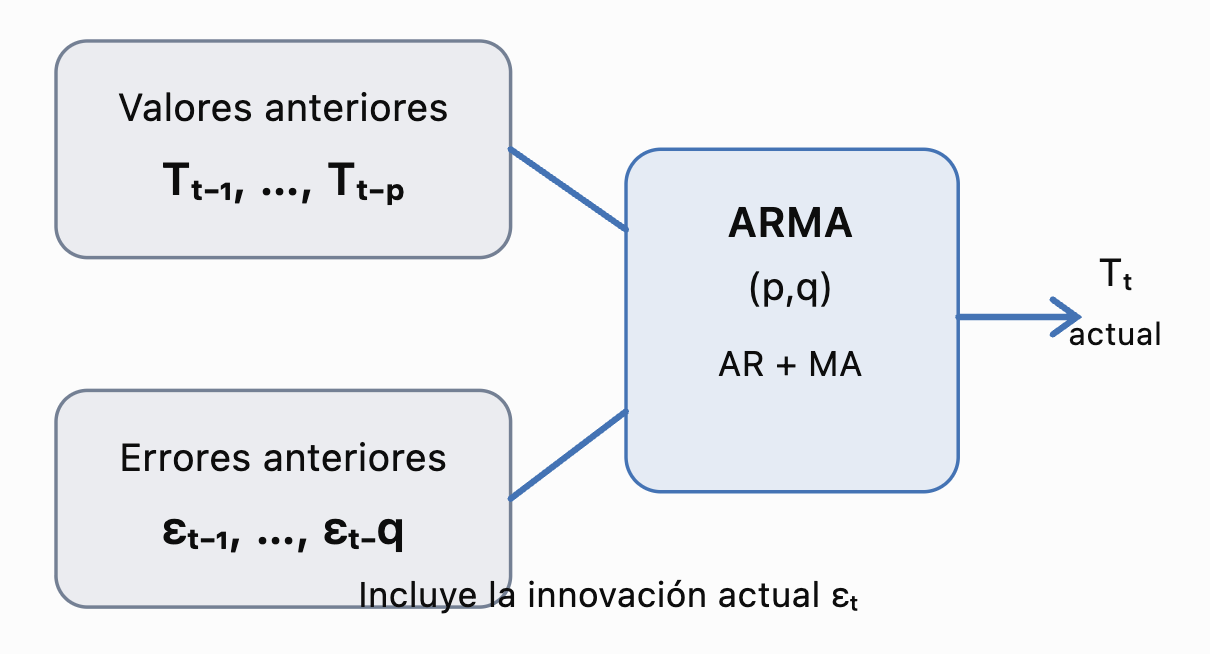

3. Formulación matemática general
La expresión matemática de un modelo ARMA(p,q) es:
$$
\boxed{
    X_t = c + \sum_{i=1}^{p}\phi_i X_{t-i} + \varepsilon_t + \sum_{j=1}^{q}\theta_j\varepsilon_{t-j}
}
$$

donde:

| Símbolo | Significado |
| :--- | :--- |
| $X_t$ | Valor de la serie temporal en el instante $t$ |
| $c$ | Constante o intercepto del modelo |
| $p$ | Orden autorregresivo |
| $q$ | Orden de medias móviles |
| $\phi_i$ | Coeficientes autorregresivos |
| $\theta_j$ | Coeficientes de medias móviles |
| $\varepsilon_t$ | Innovación aleatoria en el instante $t$ |
| $\varepsilon_{t-j}$ | Innovación correspondiente a $j$ periodos anteriores |

Se supone habitualmente que las innovaciones constituyen un proceso de ruido blanco:
$$
\varepsilon_t \sim \text{WN}(0, \sigma_{\varepsilon}^2)
$$

Esto implica:
$$
\mathbb{E}[\varepsilon_t] = 0
$$

$$
\text{Var}(\varepsilon_t) = \sigma_{\varepsilon}^2
$$

$$
\text{Cov}(\varepsilon_t, \varepsilon_s) = 0 \qquad \forall t \neq s
$$

Es importante señalar que ruido blanco no significa necesariamente ruido gaussiano. La normalidad es una hipótesis adicional que resulta útil, especialmente para la estimación por máxima verosimilitud y la construcción de intervalos predictivos.

3.1. Representación respecto de la media
Cuando el proceso es estacionario y tiene media $\mu$, resulta conveniente escribir:
$$
\boxed{
    X_t - \mu = \sum_{i=1}^{p}\phi_i(X_{t-i} - \mu) + \varepsilon_t + \sum_{j=1}^{q}\theta_j\varepsilon_{t-j}
}
$$

La constante del modelo se relaciona con la media mediante:
$$
\boxed{
    c = \mu \left(1 - \sum_{i=1}^{p}\phi_i\right)
}
$$

Esta relación es importante porque el intercepto $c$ y la media incondicional $\mu$ no son, en general, la misma cantidad.

4. Análisis de los componentes AR(p) y MA(q)
4.1. Componente autorregresivo AR(p)
El modelo AR(p) se expresa como:
$$
X_t=c+\phi_1X_{t-1}+\phi_2X_{t-2}
+\cdots+\phi_pX_{t-p}+\varepsilon_t
$$

Por ejemplo, para un AR(2):
$$
X_t=c+\phi_1X_{t-1}+\phi_2X_{t-2}
+\varepsilon_t
$$

En este caso, la observación actual depende linealmente de las dos observaciones anteriores.

Los coeficientes $\phi_1$ y $\phi_2$ permiten cuantificar cómo influyen esos valores pasados, condicionados a los demás términos del modelo.

4.2. Componente de medias móviles MA(q)
El modelo MA(q) se expresa como:
$$
X_t=\mu+\varepsilon_t+
\theta_1\varepsilon_{t-1}+\cdots+
\theta_q\varepsilon_{t-q}
$$

Por ejemplo, para un MA(2):
$$
X_t=\mu+\varepsilon_t+
\theta_1\varepsilon_{t-1}+
\theta_2\varepsilon_{t-2}
$$

Aquí es necesario distinguir entre dos conceptos:
- Una media móvil utilizada para suavizar datos mediante promedios aritméticos.
- Un modelo estadístico MA(q), que combina linealmente innovaciones aleatorias.

El componente MA(q) del modelo ARMA no es un promedio móvil convencional de observaciones.

Representa la persistencia temporal de perturbaciones no explicadas por el modelo.

5. Ejemplo matemático: modelo ARMA(2,1)
Consideremos el siguiente modelo:
$$
\boxed{
X_t=0.8+0.5X_{t-1}
+0.2X_{t-2}
+\varepsilon_t
+0.4\varepsilon_{t-1}
}
$$

Se trata de un ARMA(2,1), porque:
$$
p=2,\qquad q=1
$$

Sus parámetros son:
$$
c=0.8,\quad
\phi_1=0.5,\quad
\phi_2=0.2,\quad
\theta_1=0.4
$$

Supongamos que conocemos:
$$
X_{t-1}=25.0
$$

$$
X_{t-2}=24.5
$$

$$
\varepsilon_{t-1}=-0.3
$$

Queremos estimar el valor de $X_t$.

Paso 1. Sustitución
$$
X_t=0.8+0.5(25)+0.2(24.5)
+\varepsilon_t+0.4(-0.3)
$$

Paso 2. Cálculo de los componentes
Componente autorregresivo:
$$
0.5(25)+0.2(24.5)=17.4
$$

Componente de medias móviles:
$$
0.4(-0.3)=-0.12
$$

Por tanto:
$$
X_t=0.8+17.4-0.12+\varepsilon_t
$$

$$
X_t=18.08+\varepsilon_t
$$

Paso 3. Predicción
En el instante $t-1$, la innovación futura $\varepsilon_t$ todavía no se conoce. Su esperanza condicional es cero.

En consecuencia:
$$
\boxed{
\hat X_{t|t-1}=18.08
}
$$

El resultado corresponde a una predicción puntual de un paso adelante.

El ejemplo es ilustrativo; los coeficientes no han sido estimados a partir de datos meteorológicos reales. Además, la media incondicional del modelo sería:
$$
\mu=\frac{0.8}{1-0.5-0.2}
=2.667
$$

Esto demuestra por qué los parámetros de un modelo deben estimarse y validarse con datos: aunque la operación matemática sea correcta, los coeficientes elegidos pueden no representar adecuadamente una serie de temperatura.

6. Representación mediante el operador de rezago
Una de las formulaciones más importantes de los modelos ARMA utiliza el operador de rezago $B$, definido como:
$$
BX_t=X_{t-1}
$$

En general:
$$
B^kX_t=X_{t-k}
$$

Para las innovaciones:
$$
B^k\varepsilon_t=\varepsilon_{t-k}
$$

Definimos el polinomio autorregresivo:
$$
\phi(B)=1-\phi_1B-\phi_2B^2-\cdots-\phi_pB^p
$$

Y el polinomio de medias móviles:
$$
\theta(B)=1+\theta_1B+\theta_2B^2+\cdots+\theta_qB^q
$$

La representación compacta del modelo es:
$$
\boxed{
\phi(B)(X_t-\mu)=\theta(B)\varepsilon_t
}
$$

Esta expresión permite estudiar propiedades fundamentales del proceso, como estacionariedad, invertibilidad, autocovarianza y comportamiento de las predicciones.

Ejemplo ARMA(2,1)
Para:
$$
X_t-\mu=
0.5(X_{t-1}-\mu)
+0.2(X_{t-2}-\mu)
+\varepsilon_t+0.4\varepsilon_{t-1}
$$

Se obtiene:
$$
(1-0.5B-0.2B^2)(X_t-\mu)
=(1+0.4B)\varepsilon_t
$$

Esta representación será particularmente útil para analizar las raíces de los polinomios característicos.

7. Estacionariedad del modelo ARMA(p,q)
La estacionariedad débil es una propiedad fundamental para utilizar el modelo ARMA clásico.

Una serie es débilmente estacionaria cuando satisface:

Primera condición: media constante
$$
E[X_t]=\mu
$$

Segunda condición: varianza constante
$$
Var(X_t)=\sigma_X^2
$$

Tercera condición: autocovarianza dependiente únicamente del rezago
$$
Cov(X_t,X_{t-k})=\gamma(k)
$$

Esto significa que las propiedades estadísticas de segundo orden de la serie no dependen del instante absoluto en el que se realizan las observaciones.

7.1. Condición matemática de estacionariedad
La estacionariedad causal del modelo ARMA depende de las raíces del polinomio autorregresivo:
$$
\phi(z)=1-\phi_1z-\cdots-\phi_pz^p
$$

La condición es:
$$
\boxed{
|z_i|>1
}
$$

para todas las raíces $z_i$ de:
$$
\phi(z)=0
$$

Es decir, todas las raíces deben encontrarse fuera del círculo unitario del plano complejo.

Para el caso AR(1):
$$
X_t=\phi_1X_{t-1}+\varepsilon_t
$$

La condición se simplifica a:
$$
|\phi_1|<1
$$

Para modelos AR(p) de orden superior, no basta con exigir que cada coeficiente sea menor que uno en valor absoluto. Es necesario analizar las raíces del polinomio.

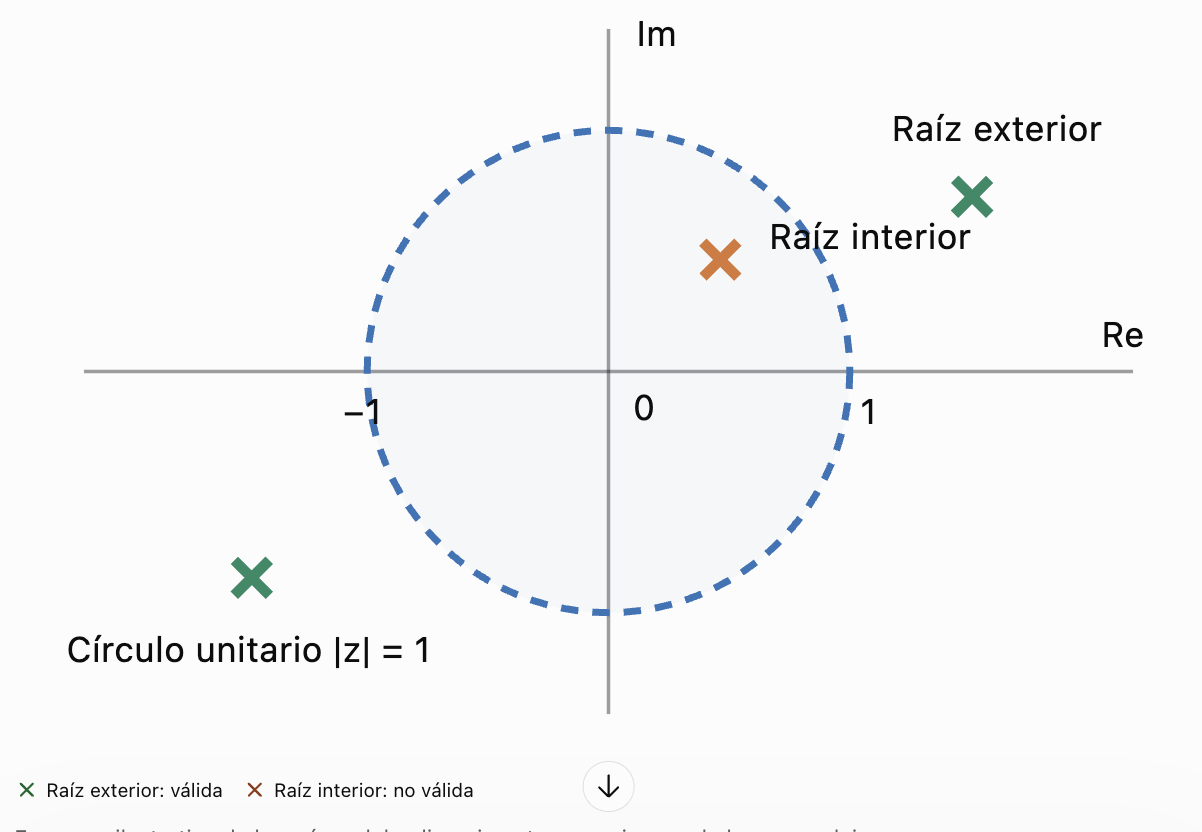

8. Invertibilidad del modelo ARMA
La invertibilidad está relacionada con el componente MA(q).

Un proceso MA es invertible cuando las innovaciones pueden reconstruirse a partir de una representación convergente de las observaciones presentes y pasadas.

Para ello, las raíces del polinomio:
$$
\theta(z)=1+\theta_1z+\cdots+\theta_qz^q
$$

deben satisfacer:
$$
\boxed{|z_i|>1}
$$

Por ejemplo, para un MA(1):
$$
X_t=\varepsilon_t+\theta_1\varepsilon_{t-1}
$$

La condición de invertibilidad es:
$$
|\theta_1|<1
$$

La invertibilidad es importante porque permite obtener una representación identificable y estable de las innovaciones a partir de la información observada.

En síntesis, deben distinguirse dos condiciones:

| Propiedad | Polinomio asociado | Condición |
| :--- | :--- | :--- |
| Estacionariedad causal | $\phi(z)$ | Raíces fuera del círculo unitario |
| Invertibilidad | $\theta(z)$ | Raíces fuera del círculo unitario |

En un modelo ARMA mínimo se supone además que los polinomios AR y MA no tienen raíces comunes, para evitar cancelaciones y parámetros redundantes.

9. Función de autocorrelación ACF y autocorrelación parcial PACF
Las funciones ACF y PACF son herramientas esenciales para identificar los órdenes $p$ y $q$.

La función de autocorrelación se define como:
$$
\boxed{
\rho(k)=\frac{\gamma(k)}{\gamma(0)}
}
$$

donde:
$$
\gamma(k)=Cov(X_t,X_{t-k})
$$

La PACF mide la asociación lineal entre $X_t$ y $X_{t-k}$, después de controlar los rezagos intermedios.

9.1. Comportamiento teórico

| Modelo | ACF | PACF |
| :--- | :--- | :--- |
| **AR(p)** | Decaimiento gradual, exponencial o amortiguado | Corte después del rezago $p$ |
| **MA(q)** | Corte después del rezago $q$ | Decaimiento gradual |
| **ARMA(p,q)** | Generalmente decaimiento gradual | Generalmente decaimiento gradual |

En modelos ARMA, la identificación es más compleja porque ambas funciones pueden mostrar estructuras de decaimiento.

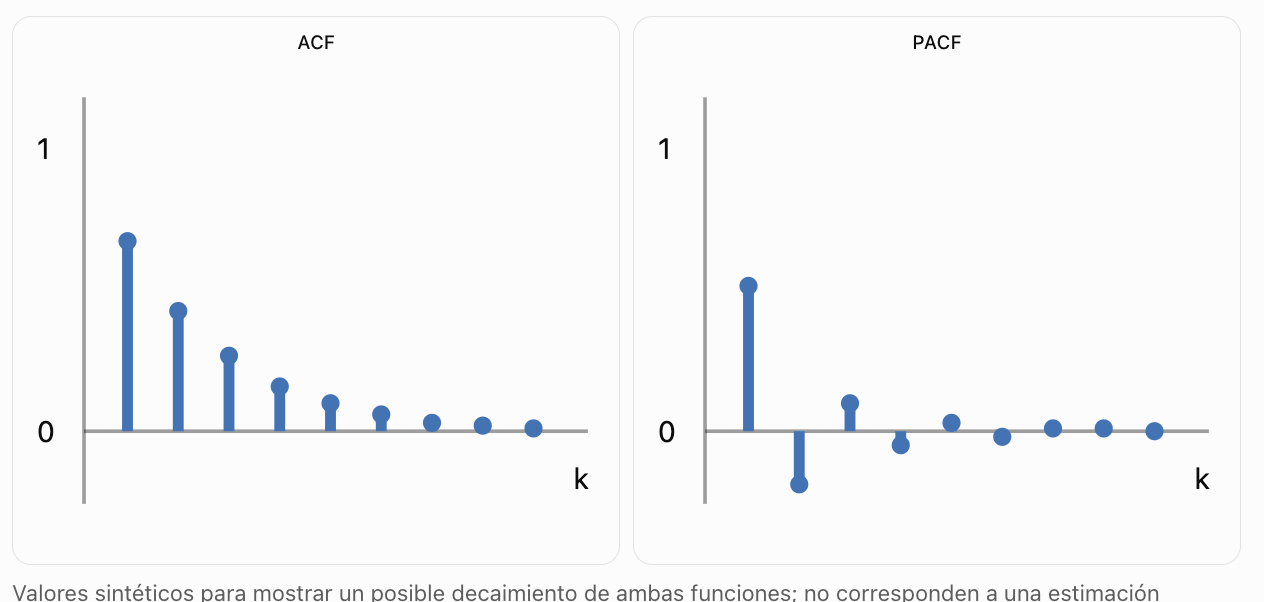

10. Estimación de parámetros de un modelo ARMA(p,q)
Supongamos que disponemos de $n$ observaciones:
$$
X_1, X_2, \ldots, X_n
$$

El objetivo consiste en estimar el conjunto de parámetros:
$$
\boldsymbol{\beta} = (c, \phi_1, \ldots, \phi_p, \theta_1, \ldots, \theta_q, \sigma_{\varepsilon}^2)
$$

Existen varios procedimientos de estimación.

10.1. Máxima verosimilitud
Uno de los métodos más utilizados es la estimación por máxima verosimilitud (*Maximum Likelihood Estimation*, MLE).

Bajo el supuesto de innovaciones gaussianas, se construye una función de verosimilitud que cuantifica qué tan compatibles son los datos observados con los parámetros propuestos.

En una formulación condicional simplificada:
$$
L(\boldsymbol{\beta}) = \prod_{t=m+1}^{n} \frac{1}{\sqrt{2\pi\sigma_{\varepsilon}^2}} \exp\left( -\frac{\varepsilon_t^2}{2\sigma_{\varepsilon}^2} \right)
$$

donde $m$ representa el número de observaciones iniciales condicionadas y las innovaciones se calculan recursivamente.

Aplicando logaritmos:
$$
\ell(\boldsymbol{\beta}) = -\frac{n-m}{2}\ln(2\pi) -\frac{n-m}{2}\ln(\sigma_{\varepsilon}^2) - \frac{1}{2\sigma_{\varepsilon}^2} \sum_{t=m+1}^{n}\varepsilon_t^2
$$

El objetivo es encontrar:
$$
\boxed{
    \hat{\boldsymbol{\beta}} = \arg\max_{\boldsymbol{\beta}} \ell(\boldsymbol{\beta})
}
$$

La verosimilitud exacta, utilizada por diversas implementaciones modernas, considera además la distribución de los estados iniciales y la estructura de covarianza del proceso.

10.2. Mínimos cuadrados condicionales
Otro procedimiento consiste en minimizar la suma de los cuadrados de las innovaciones estimadas:
$$
\boxed{
    S(\boldsymbol{\beta}) = \sum_{t=m+1}^{n} \hat{\varepsilon}_t^2
}
$$

A diferencia de una regresión lineal ordinaria, la estimación ARMA generalmente requiere optimización numérica iterativa porque las innovaciones pasadas no se observan directamente.

11. Selección del orden del modelo: criterios AIC y BIC
Una pregunta fundamental es:

¿Cómo determinar los valores apropiados de $p$ y $q$?

Por ejemplo, podríamos considerar:
$$
ARMA(1,1),\ ARMA(2,1),\ ARMA(2,2),\ ARMA(3,1)
$$

Para comparar estos modelos se utilizan criterios de información.

Criterio de Akaike
$$
\boxed{
AIC=-2\ln(\hat L)+2k
}
$$

Criterio bayesiano de Schwarz
$$
\boxed{
BIC=-2\ln(\hat L)+k\ln(n)
}
$$

donde:
- $\hat L$: máxima verosimilitud del modelo.
- $k$: número de parámetros estimados contabilizados en el criterio.
- $n$: número de observaciones utilizadas.

Ambos criterios equilibran el ajuste estadístico con la complejidad del modelo.

En general, se prefiere el modelo con menor AIC o BIC entre modelos estimados sobre datos comparables.

Ejemplo ilustrativo

| Modelo | AIC | BIC |
| :--- | :--- | :--- |
| **ARMA(1,1)** | 1280.5 | 1298.2 |
| **ARMA(2,1)** | 1242.3 | 1264.5 |
| **ARMA(2,2)** | 1240.8 | 1267.4 |
| **ARMA(3,2)** | 1241.6 | 1272.7 |

En este ejemplo hipotético:
- El menor AIC corresponde al ARMA(2,2).
- El menor BIC corresponde al ARMA(2,1).

Esto no implica que uno de ellos sea automáticamente el mejor predictor. La decisión final debe incorporar diagnóstico residual y evaluación fuera de muestra.

12. Predicción mediante un modelo ARMA(p,q)
Una vez estimados los parámetros, podemos utilizar el modelo para pronosticar valores futuros.

Para un modelo ARMA(2,1):
$$
X_t=c+\phi_1X_{t-1}+\phi_2X_{t-2}
+\varepsilon_t+\theta_1\varepsilon_{t-1}
$$

12.1. Predicción de un paso adelante
Con información disponible hasta el instante $t$:
$$
\boxed{
\hat X_{t+1|t}
=c+\phi_1X_t+\phi_2X_{t-1}
+\theta_1\hat\varepsilon_t
}
$$

La innovación futura tiene esperanza condicional cero:
$$
E[\varepsilon_{t+1}\mid\mathcal F_t]=0
$$

12.2. Predicción de dos pasos adelante
$$
\boxed{
\hat X_{t+2|t}
=c+\phi_1\hat X_{t+1|t}
+\phi_2X_t
}
$$

Para dos pasos adelante, los términos de innovación correspondientes a $t+1$ y $t+2$ tienen esperanza condicional cero.

12.3. Predicción de tres pasos adelante
$$
\hat X_{t+3|t}
=c+\phi_1\hat X_{t+2|t}
+\phi_2\hat X_{t+1|t}
$$

En general, a medida que aumenta el horizonte de predicción, la incertidumbre crece y las predicciones de un modelo ARMA estacionario tienden hacia la media incondicional $\mu$.

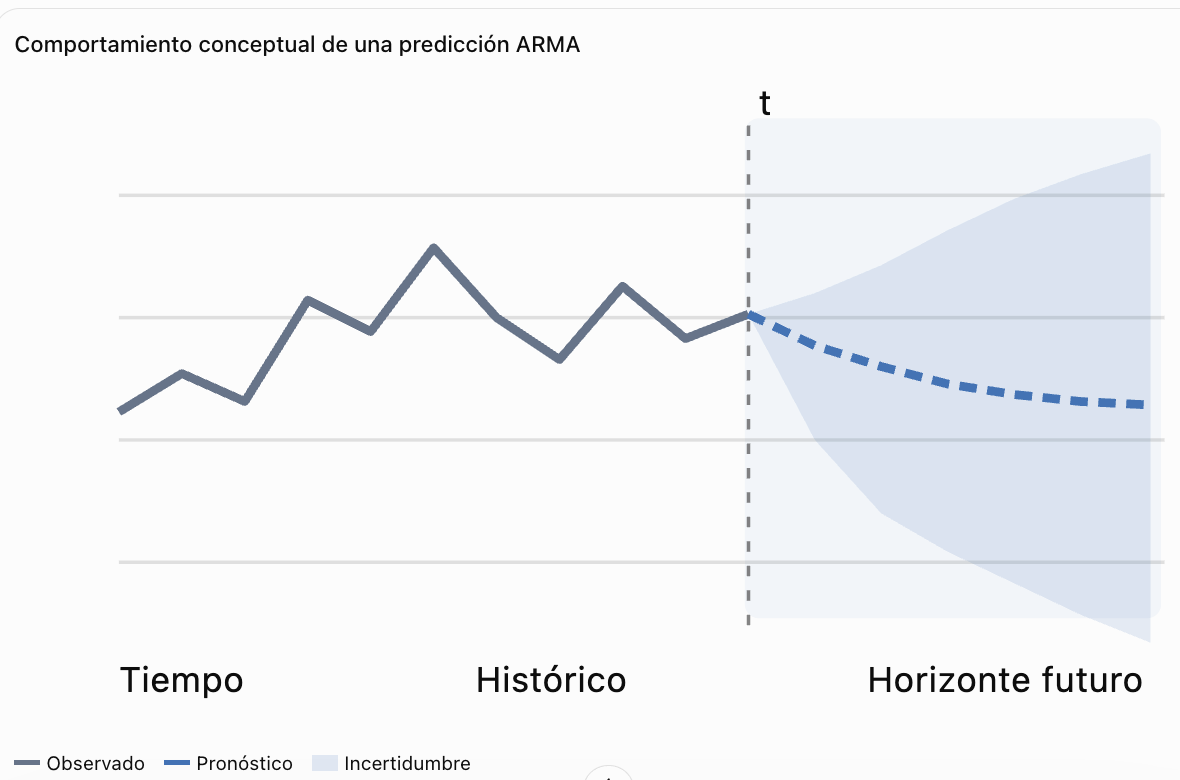

13. Evaluación de la calidad predictiva
Después de estimar un modelo ARMA, es necesario evaluar su desempeño.

Sea:
$$
e_t=X_t-\hat X_t
$$

el error de predicción.

Error absoluto medio (MAE)
$$
\boxed{
MAE=\frac{1}{n}\sum_{t=1}^{n}|e_t|
}
$$

Raíz del error cuadrático medio (RMSE)
$$
\boxed{
RMSE=
\sqrt{\frac{1}{n}\sum_{t=1}^{n}e_t^2}
}
$$

Coeficiente de determinación
$$
\boxed{
R^2=1-
\frac{\sum_{t=1}^{n}(X_t-\hat X_t)^2}
{\sum_{t=1}^{n}(X_t-\bar X)^2}
}
$$

El $R^2$ puede emplearse como medida descriptiva complementaria, pero en series temporales es recomendable dar mayor importancia a MAE, RMSE y al desempeño frente a modelos de referencia.

Además, las predicciones deben evaluarse sobre datos que no hayan participado en el ajuste.

14. Análisis de residuales
Un modelo ARMA correctamente especificado debe producir innovaciones estimadas que se comporten aproximadamente como ruido blanco.

Esto significa que no debería permanecer una estructura de dependencia temporal aprovechable en los residuales.

14.1. Media de los residuales
$$
E[\hat\varepsilon_t]\approx0
$$

14.2. Autocorrelación residual
$$
\rho_{\hat\varepsilon}(k)\approx0
\qquad k>0
$$

14.3. Prueba de Ljung-Box
Una prueba utilizada para evaluar autocorrelación conjunta es la de Ljung-Box:
$$
\boxed{
Q=n(n+2)\sum_{k=1}^{h}
\frac{\hat\rho_k^2}{n-k}
}
$$

donde:
- $n$: número de residuales.
- $h$: número de rezagos examinados.
- $\hat\rho_k$: autocorrelación residual en el rezago $k$.

Las hipótesis son:
$$
H_0:\rho_1=\rho_2=\cdots=\rho_h=0
$$

$$
H_1:\text{al menos una autocorrelación es distinta de cero}
$$

Un valor $p>0.05$ indica que no existe evidencia estadística suficiente para rechazar la hipótesis nula al nivel de significancia del 5 %.

Sin embargo, esto no demuestra que los residuales sean independientes ni garantiza que el modelo sea óptimo.

También conviene examinar la estabilidad de la varianza, los valores atípicos y, cuando sea pertinente, la distribución de los residuales.

15. Diferencias entre AR, MA, ARMA y ARIMA

| Modelo | Estructura | Aplicación |
| :--- | :--- | :--- |
| **AR(p)** | Valores pasados de la serie | Dependencia autorregresiva |
| **MA(q)** | Innovaciones actuales y pasadas | Dependencia de perturbaciones |
| **ARMA(p,q)** | AR + MA | Series estacionarias con dependencia mixta |
| **ARIMA(p,d,q)** | ARMA + diferenciación | Series que requieren diferenciación para alcanzar estacionariedad |

La relación entre ARMA y ARIMA es particularmente importante.

Un ARIMA(p,d,q) se expresa como:
$$
\boxed{
\phi(B)(1-B)^dX_t
=c+\theta(B)\varepsilon_t
}
$$

Cuando:
$$
d=0
$$

obtenemos:
$$
\boxed{
ARIMA(p,0,q)=ARMA(p,q)
}
$$

Por tanto, el modelo ARMA puede interpretarse como un caso particular del modelo ARIMA.

6. Aplicación del modelo ARMA a series de temperatura y humedad relativa
Consideremos ahora una aplicación a las series meteorológicas que hemos venido estudiando.

Supongamos que tenemos registros de temperatura ambiental:
$$
T_1,T_2,\ldots,T_n
$$

adquiridos aproximadamente cada cinco minutos.

Podríamos plantear un modelo ARMA(2,1):
$$
\boxed{
T_t=c+\phi_1T_{t-1}
+\phi_2T_{t-2}
+\varepsilon_t
+\theta_1\varepsilon_{t-1}
}
$$

La interpretación física y estadística sería la siguiente:

Primer componente:
$$
\phi_1T_{t-1}
$$

Representa la influencia lineal de la temperatura registrada cinco minutos antes.

Segundo componente:
$$
\phi_2T_{t-2}
$$

Representa la influencia de la temperatura registrada diez minutos antes.

Tercer componente:
$$
\theta_1\varepsilon_{t-1}
$$

Representa la contribución de la innovación del instante anterior a la temperatura actual.

Cuarto componente:
$$
\varepsilon_t
$$

Representa la innovación no anticipada en el instante actual.

Es importante aclarar que una innovación estadística no necesariamente corresponde a un fenómeno físico individual. Puede reunir efectos de múltiples variables omitidas, ruido de medición y variabilidad ambiental.

16.1. Consideración importante: estacionalidad meteorológica
Las series de temperatura suelen presentar ciclos diarios y estacionales.

Por ejemplo:
$$
T_t=\text{tendencia}+\text{componente periódico}+\text{fluctuación}
$$

Un ARMA clásico puede ser insuficiente cuando existen ciclos diarios pronunciados.

Si el muestreo es estrictamente regular cada cinco minutos, un ciclo diario corresponde a:
$$
s=\frac{24(60)}{5}=288
$$

observaciones.

En ese caso, podemos considerar un modelo SARIMA o eliminar previamente la componente estacional y modelar el proceso residual mediante ARMA.

También debemos verificar los intervalos reales de adquisición, porque los registros faltantes o los intervalos irregulares afectan la interpretación de los rezagos.

17. Metodología para desarrollar un modelo ARMA(p,q)
Para construir un modelo científicamente defendible, propongo el siguiente flujo metodológico:
1. Adquisición y depuración de datos
   
   Verificar fechas, frecuencia de muestreo, datos faltantes, duplicados y valores atípicos.
2. Análisis exploratorio de la serie
   
   Examinar gráficamente tendencia, estacionalidad, distribución y variabilidad temporal.
3. Evaluación de estacionariedad
   
   Aplicar pruebas ADF y KPSS, complementadas con inspección gráfica.
4. Identificación de órdenes p y q
   
   Analizar ACF y PACF y establecer un conjunto de modelos candidatos.
5. Estimación de parámetros
   
   Ajustar los modelos mediante máxima verosimilitud y verificar estacionariedad e invertibilidad.
6. Selección del modelo
   
   Comparar AIC, BIC, parsimonia y comportamiento de los residuales.
7. Validación temporal
   
   Utilizar particiones cronológicas y, preferentemente, evaluación de origen móvil o expansivo.
8. Predicción y evaluación
   
   Calcular MAE, RMSE, intervalos predictivos y comparar contra modelos de referencia como persistencia, AR y MA.

### 18. Ventajas y limitaciones del modelo ARMA

| Ventajas | Limitaciones |
| :--- | :--- |
| Formulación matemática interpretable | Requiere estacionariedad en su forma clásica |
| Relativamente eficiente computacionalmente | Modela únicamente relaciones lineales |
| Combina memoria de observaciones y perturbaciones | Puede ser insuficiente ante estacionalidad compleja |
| Permite pronósticos e intervalos de predicción | Sensible a cambios estructurales |
| Constituye una referencia estadística sólida | La identificación de órdenes puede resultar ambigua |

19. Conclusiones
El modelo ARMA(p,q) representa una evolución conceptual respecto de los modelos AR(p) y MA(q), porque incorpora simultáneamente dos fuentes de dependencia temporal: la información contenida en observaciones pasadas y la información asociada con innovaciones anteriores.

Su formulación general es:
$$
\boxed{
    X_t = c + \sum_{i=1}^{p}\phi_i X_{t-i} + \varepsilon_t + \sum_{j=1}^{q}\theta_j\varepsilon_{t-j}
}
$$

Desde el punto de vista estadístico, su correcta utilización exige estudiar la estacionariedad, la invertibilidad, la identificación de parámetros, el comportamiento de los residuales y la capacidad predictiva fuera de muestra.

Desde el punto de vista de la ingeniería, constituye una herramienta particularmente útil para modelar procesos con memoria temporal y perturbaciones aleatorias, siempre que la estructura lineal y estacionaria resulte razonable.

Estimación de parámetros, cálculo de innovaciones y generación de predicciones en un modelo ARMA(2,1)

Estudiaremos detalladamente cómo estimar los parámetros $\phi_1, \phi_2, \theta_1$ de un modelo ARMA(2,1), cómo reconstruir las innovaciones a partir de las observaciones y cómo utilizar los parámetros estimados para generar predicciones.

El aspecto matemático más importante es que los parámetros autorregresivos y de medias móviles se estiman conjuntamente, debido a que las innovaciones pasadas no son directamente observables.

1. Formulación del modelo
Consideremos una serie temporal estacionaria:
$$
X_1, X_2, \ldots, X_n
$$

El modelo ARMA(2,1) está definido por:
$$
\boxed{
    X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \varepsilon_t + \theta_1 \varepsilon_{t-1}
}
\tag{1}
$$

Sus componentes son:

| Parámetro | Interpretación |
| :--- | :--- |
| $c$ | Intercepto del modelo |
| $\phi_1$ | Influencia del primer rezago de la serie |
| $\phi_2$ | Influencia del segundo rezago |
| $\theta_1$ | Influencia de la innovación anterior |
| $\varepsilon_t$ | Innovación aleatoria actual |
| $\sigma_\varepsilon^2$ | Varianza de las innovaciones |

Supondremos inicialmente que:
$$
\varepsilon_t \sim \text{WN}(0, \sigma_\varepsilon^2)
$$

y que el proceso satisface las condiciones de estacionariedad e invertibilidad.

2. ¿Por qué no podemos estimar directamente los parámetros mediante regresión lineal ordinaria?

Para un modelo AR(2), tenemos:
$$
X_t = c + \phi_1 X_{t-1} + \phi_2 X_{t-2} + \varepsilon_t
$$

Podemos construir una matriz de regresores:
$$
\mathbf{Z} =
\begin{bmatrix}
1 & X_2 & X_1 \\
1 & X_3 & X_2 \\
\vdots & \vdots & \vdots \\
1 & X_{n-1} & X_{n-2}
\end{bmatrix}
$$

y estimar sus parámetros mediante mínimos cuadrados ordinarios:
$$
\hat{\boldsymbol{\beta}} = (\mathbf{Z}^\top \mathbf{Z})^{-1} \mathbf{Z}^\top \mathbf{y}
$$

siempre que la matriz tenga rango completo.

Sin embargo, en ARMA(2,1) aparece un término adicional:
$$
\theta_1 \varepsilon_{t-1}
$$

El problema es que $\varepsilon_{t-1}$ no es una variable observada directamente.

No disponemos de una columna de innovaciones verdaderas en nuestro conjunto de datos.

Por tanto, debemos calcularlas a partir de parámetros provisionales y de la información temporal disponible.

Esto convierte el problema en uno de optimización no lineal.

3. Primera etapa: estimación de la media y centrado de la serie

Aunque podemos trabajar con el intercepto $c$, es conveniente comenzar con una representación centrada.

Definimos:
$$
Y_t = X_t - \mu
$$

donde $\mu$ representa la media incondicional del proceso.

Entonces:
$$
\boxed{
    Y_t = \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \varepsilon_t + \theta_1 \varepsilon_{t-1}
}
\tag{2}
$$

Si el proceso es estacionario:
$$
\mu = \frac{c}{1 - \phi_1 - \phi_2}
$$

y, por tanto:
$$
c = \mu(1 - \phi_1 - \phi_2)
$$

La media muestral:
$$
\bar{X} = \frac{1}{n}\sum_{t=1}^{n} X_t
$$

puede utilizarse como una estimación preliminar de $\mu$.

Sin embargo, en una estimación formal por máxima verosimilitud, la media también puede estimarse conjuntamente con los demás parámetros.

Para simplificar los cálculos que siguen, trabajaremos con la serie centrada $Y_t$.

4. Segunda etapa: cálculo recursivo de las innovaciones

A partir de la ecuación (2), despejamos la innovación actual:
$$
\boxed{
    \varepsilon_t =
    Y_t - \phi_1 Y_{t-1} - \phi_2 Y_{t-2} - \theta_1 \varepsilon_{t-1}
}
\tag{3}
$$

Esta es una de las ecuaciones más importantes del procedimiento.

Permite calcular las innovaciones secuencialmente, siempre que se disponga de valores provisionales de los parámetros y de una condición inicial.

4.1. Inicialización
Para realizar una estimación condicional sencilla, podemos establecer:
$$
\hat{\varepsilon}_2 = 0
$$

y comenzar la recursión en $t=3$.

Entonces:
$$
\hat{\varepsilon}_3 =
Y_3 - \phi_1 Y_2 - \phi_2 Y_1
$$

Para el instante siguiente:
$$
\hat{\varepsilon}_4 =
Y_4 - \phi_1 Y_3 - \phi_2 Y_2 - \theta_1 \hat{\varepsilon}_3
$$

Para $t=5$:
$$
\hat{\varepsilon}_5 =
Y_5 - \phi_1 Y_4 - \phi_2 Y_3 - \theta_1 \hat{\varepsilon}_4
$$

Y así sucesivamente.

Es importante precisar que estas son innovaciones estimadas condicionalmente, no las innovaciones verdaderas del proceso.

La elección de las condiciones iniciales afecta los primeros cálculos. En muestras grandes, y bajo invertibilidad, su influencia suele disminuir progresivamente.

5. Ejemplo numérico del cálculo de innovaciones

Consideremos la siguiente serie centrada de siete observaciones:

| $t$ | $Y_t$ |
| :--- | :--- |
| 1 | 0.20 |
| 2 | 0.50 |
| 3 | 0.40 |
| 4 | 0.80 |
| 5 | 0.60 |
| 6 | 0.30 |
| 7 | 0.50 |

Supongamos inicialmente los siguientes parámetros provisionales:
$$
\phi_1 = 0.50, \qquad \phi_2 = 0.20, \qquad \theta_1 = 0.40
$$

Estos valores son hipotéticos; todavía no constituyen estimaciones obtenidas mediante optimización.

### Innovación en $t=3$
$$
\hat{\varepsilon}_3 = 0.40 - 0.50(0.50) - 0.20(0.20)
$$

$$
\hat{\varepsilon}_3 = 0.40 - 0.25 - 0.04
$$

$$
\boxed{\hat{\varepsilon}_3 = 0.1100}
$$

### Innovación en $t=4$
$$
\hat{\varepsilon}_4 = 0.80 - 0.50(0.40) - 0.20(0.50) - 0.40(0.1100)
$$

$$
\boxed{\hat{\varepsilon}_4 = 0.4560}
$$

### Innovación en $t=5$
$$
\hat{\varepsilon}_5 = 0.60 - 0.50(0.80) - 0.20(0.40) - 0.40(0.4560)
$$

$$
\boxed{\hat{\varepsilon}_5 = -0.0624}
$$

### Innovación en $t=6$
$$
\hat{\varepsilon}_6 = 0.30 - 0.50(0.60) - 0.20(0.80) - 0.40(-0.0624)
$$

$$
\boxed{\hat{\varepsilon}_6 = -0.13504}
$$

### Innovación en $t=7$
$$
\hat{\varepsilon}_7 = 0.50 - 0.50(0.30) - 0.20(0.60) - 0.40(-0.13504)
$$

$$
\boxed{\hat{\varepsilon}_7 = 0.284016}
$$

Los resultados se resumen en la siguiente tabla:

| $t$ | $Y_t$ | $\hat{\varepsilon}_t$ |
| :--- | :--- | :--- |
| 3 | 0.40 | 0.110000 |
| 4 | 0.80 | 0.456000 |
| 5 | 0.60 | -0.062400 |
| 6 | 0.30 | -0.135040 |
| 7 | 0.50 | 0.284016 |

Observemos que cada innovación depende de la innovación calculada inmediatamente antes.

Esta dependencia recursiva explica por qué la estimación del componente MA es más compleja que la de un modelo puramente autorregresivo.

6. Tercera etapa: estimación de $\phi_1, \phi_2, \theta_1$

Once establecida la forma de calcular las innovaciones, podemos formular un problema de optimización.

6.1. Función objetivo de mínimos cuadrados condicionales

Definimos:
$$
S(\phi_1, \phi_2, \theta_1) = \sum_{t=3}^{n} \hat{\varepsilon}_t^2
$$

donde las innovaciones dependen recursivamente de los parámetros:
$$
\hat{\varepsilon}_t = Y_t - \phi_1 Y_{t-1} - \phi_2 Y_{t-2} - \theta_1 \hat{\varepsilon}_{t-1}
$$

Nuestro objetivo consiste en encontrar:
$$
\boxed{
    (\hat{\phi}_1, \hat{\phi}_2, \hat{\theta}_1) = \arg\min_{\phi_1, \phi_2, \theta_1} S(\phi_1, \phi_2, \theta_1)
}
\tag{4}
$$

La idea es encontrar los coeficientes que produzcan innovaciones estimadas con la menor suma de cuadrados posible, dentro de la especificación del modelo.

6.2. ¿Cómo se realiza la optimización?

El procedimiento computacional es iterativo:

**Algoritmo de estimación ARMA(2,1)**
1. Seleccionar valores iniciales para $\phi_1, \phi_2, \theta_1$.
2. Calcular todas las innovaciones mediante la ecuación recursiva.
3. Evaluar la suma de cuadrados $S$.
4. Modificar los parámetros mediante un algoritmo de optimización numérica.
5. Repetir hasta cumplir un criterio de convergencia.
6. Verificar estacionariedad, invertibilidad y diagnóstico residual.

Pueden emplearse algoritmos como BFGS, L-BFGS-B o métodos de optimización no lineal con restricciones.

Para ARMA(2,1), las condiciones de estacionariedad de la parte AR(2) pueden expresarse como:
$$
-1 < \phi_2 < 1
$$

$$
\phi_1 + \phi_2 < 1
$$

$$
\phi_2 - \phi_1 < 1
$$

Mientras que para la parte MA(1):
$$
|\theta_1| < 1
$$

Estas restricciones permiten limitar la búsqueda a modelos causales estacionarios e invertibles.

6.3. ¿Por qué es necesaria la optimización conjunta?

Supongamos que modificamos $\theta_1$.

De acuerdo con la ecuación (3), esto modifica $\hat{\varepsilon}_t$. A su vez, la nueva innovación modifica el cálculo de $\hat{\varepsilon}_{t+1}$, y así sucesivamente.

Por tanto, la función objetivo depende de los tres parámetros de manera acoplada y no lineal.

No podemos estimar $\phi_1, \phi_2$ mediante una regresión ordinaria y después estimar $\theta_1$ de forma independiente esperando, en general, obtener la solución óptima conjunta.

7. Estimación por máxima verosimilitud
En aplicaciones estadísticas formales suele preferirse la estimación por máxima verosimilitud.

Bajo el supuesto:
$$
\varepsilon_t \overset{\text{iid}}{\sim} N(0, \sigma_{\varepsilon}^2)
$$

la función de log-verosimilitud condicional, para la recursión inicializada en $t=3$, es:
$$
\ell =
-\frac{n-2}{2}\ln(2\pi)
-\frac{n-2}{2}\ln(\sigma_{\varepsilon}^2)
-\frac{1}{2\sigma_{\varepsilon}^2}
\sum_{t=3}^{n}\hat{\varepsilon}_t^2
$$

Si los parámetros son fijos, el estimador condicional de la varianza es:
$$
\boxed{
\hat{\sigma}_{\varepsilon}^2 =
\frac{1}{n-2}\sum_{t=3}^{n}\hat{\varepsilon}_t^2
}
$$

Este es el estimador de máxima verosimilitud condicional de la varianza bajo esa formulación; no es una corrección insesgada por grados de libertad.

Sustituyendo esta expresión en la log-verosimilitud, minimizar la suma de cuadrados equivale a maximizar la verosimilitud condicional concentrada.

No obstante, la verosimilitud gaussiana exacta incorpora la distribución de las condiciones iniciales y puede proporcionar resultados distintos, especialmente en muestras pequeñas.

8. Cuarta etapa: generación de predicciones
Una vez estimados los parámetros, el modelo se utiliza para pronosticar valores futuros.

Supongamos que hemos obtenido:
$$
\hat{\phi}_1 = 0.50, \qquad
\hat{\phi}_2 = 0.20, \qquad
\hat{\theta}_1 = 0.40
$$

Utilizaremos nuevamente estos valores únicamente para ilustrar el procedimiento predictivo.

Nuestro modelo centrado es:
$$
Y_t = 0.50 Y_{t-1} + 0.20 Y_{t-2} + \varepsilon_t + 0.40 \varepsilon_{t-1}
$$

8.1. Predicción de un paso adelante
En el instante $t=7$, conocemos:
$$
Y_7 = 0.50, \quad Y_6 = 0.30, \quad
\hat{\varepsilon}_7 = 0.284016
$$

La predicción para $t=8$ es:
$$
\hat{Y}_{8|7} = 0.50 Y_7 + 0.20 Y_6 + 0.40 \hat{\varepsilon}_7
$$

Sustituyendo:
$$
\hat{Y}_{8|7} = 0.50(0.50) + 0.20(0.30) + 0.40(0.284016)
$$

$$
\boxed{\hat{Y}_{8|7} = 0.4236064}
$$

8.2. Predicción de dos pasos adelante
Para $t=9$, la innovación $\varepsilon_8$ es desconocida y su esperanza condicional es cero.

Por tanto:
$$
\hat{Y}_{9|7} = 0.50 \hat{Y}_{8|7} + 0.20 Y_7
$$

$$
= 0.50(0.4236064) + 0.20(0.50)
$$

$$
\boxed{\hat{Y}_{9|7} = 0.3118032}
$$

8.3. Predicción de tres pasos adelante
$$
\hat{Y}_{10|7} = 0.50 \hat{Y}_{9|7} + 0.20 \hat{Y}_{8|7}
$$

$$
= 0.50(0.3118032) + 0.20(0.4236064)
$$

$$
\boxed{\hat{Y}_{10|7} = 0.24062288}
$$

### Resumen de Resultados

| Horizonte | Predicción centrada |
| :--- | :--- |
| $t+1$ | $0.423606$ |
| $t+2$ | $0.311803$ |
| $t+3$ | $0.240623$ |

Si la serie original tuviera una media $\mu = 25\,^\circ\text{C}$, las predicciones en la escala original serían:
$$
\hat{X}_{t+h|t} = \mu + \hat{Y}_{t+h|t}
$$

Por ejemplo:
$$
\hat{X}_{8|7} = 25 + 0.4236064
$$

$$
\boxed{\hat{X}_{8|7} = 25.4236064\,^\circ\text{C}
}
$$

Las predicciones sucesivas tienden a la media del proceso cuando el modelo es estacionario y el horizonte aumenta.

9. Incertidumbre de las predicciones
Además de las predicciones puntuales, es importante cuantificar su incertidumbre.

Un modelo ARMA causal e invertible puede expresarse como un proceso MA infinito:
$$
Y_t = \psi(B)\varepsilon_t
$$

donde:
$$
\psi(B) = \frac{\theta(B)}{\phi(B)}
$$

Para ARMA(2,1):
$$
\psi(B) = \frac{1 + \theta_1 B}{1 - \phi_1 B - \phi_2 B^2}
$$

Al expandir:
$$
\psi(B) = 1 + \psi_1 B + \psi_2 B^2 + \cdots
$$

obtenemos:
$$
\psi_0 = 1
$$

$$
\psi_1 = \phi_1 + \theta_1
$$

$$
\psi_2 = \phi_1 \psi_1 + \phi_2
$$

y, para $j \geq 2$:
$$
\psi_j = \phi_1 \psi_{j-1} + \phi_2 \psi_{j-2}
$$

La varianza del error de predicción a $h$ pasos es:
$$
\boxed{
\text{Var}(e_{t+h|t}) =
\sigma_{\varepsilon}^2
\sum_{j=0}^{h-1}\psi_j^2
}
\tag{5}
$$

Esta expresión supone parámetros conocidos y no incorpora la incertidumbre derivada de su estimación.

Para un paso:
$$
\text{Var}(e_{t+1|t}) = \sigma_{\varepsilon}^2
$$

Para dos pasos:
$$
\text{Var}(e_{t+2|t}) = \sigma_{\varepsilon}^2 (1 + \psi_1^2)
$$

Bajo normalidad, un intervalo predictivo aproximado del 95 % es:
$$
\boxed{
\hat{X}_{t+h|t} \pm 1.96 \sqrt{\text{Var}(e_{t+h|t})}
}
$$

Esto permite expresar no solamente el valor esperado de la temperatura futura, sino también un rango de incertidumbre asociado.

12. Diferencia entre error residual, innovación y error de predicción
Aunque estos términos suelen utilizarse de manera intercambiable, conviene distinguirlos.

Innovación teórica:
$$
\varepsilon_t=
X_t-E[X_t\mid\mathcal F_{t-1}]
$$

Es la parte de $X_t$ que no puede anticiparse mediante la información pasada del proceso.

Innovación estimada:
$$
\hat\varepsilon_t=
X_t-\hat X_{t|t-1}
$$

Es una aproximación calculada a partir del modelo ajustado y su procedimiento de filtrado.

Error de predicción a $h$ pasos:
$$
e_{t+h|t}=
X_{t+h}-\hat X_{t+h|t}
$$

Para $h=1$, el error de predicción coincide conceptualmente con la innovación cuando se utilizan el modelo verdadero y la información correcta.

Para horizontes superiores, el error de predicción generalmente combina varias innovaciones futuras.

Síntesis del procedimiento matemático
El desarrollo completo de un ARMA(2,1) puede resumirse mediante tres ecuaciones fundamentales.

Estimación de parámetros:
$$
\boxed{
\hat{\boldsymbol{\beta}}
=
\arg\min_{\boldsymbol{\beta}}
\sum_{t=3}^{n}
\hat\varepsilon_t^2
}
$$

Cálculo recursivo de innovaciones:
$$
\boxed{
\hat\varepsilon_t=
Y_t-\hat\phi_1Y_{t-1}
-\hat\phi_2Y_{t-2}
-\hat\theta_1\hat\varepsilon_{t-1}
}
$$

Predicción de un paso adelante:
$$
\boxed{
\hat Y_{t+1|t}
=
\hat\phi_1Y_t+
\hat\phi_2Y_{t-1}+
\hat\theta_1\hat\varepsilon_t
}
$$

Estas tres expresiones muestran la relación entre los parámetros, las innovaciones y la capacidad predictiva del modelo.

El siguiente programa implementa un análisis estadístico y predictivo de la temperatura ambiental mediante un modelo ARMA(2,1), utilizando statsmodels para estimar sus parámetros por máxima verosimilitud.

El programa está preparado para cargar un archivo CSV o Excel desde Google Colab y realizar las siguientes operaciones:
1. Importación, identificación y depuración de la serie de temperatura.
2. Análisis de estacionariedad mediante ADF y KPSS.
3. Construcción de la tabla de observaciones rezagadas $T_t, T_{t-1}, T_{t-2}$.
4. Estimación de $\phi_1, \phi_2, \theta_1$, intercepto y varianza de innovaciones.
5. Cálculo de innovaciones estimadas y valores ajustados.
6. Obtención de AIC, BIC y log-verosimilitud.
7. Análisis residual mediante ACF, PACF, histograma, gráfico Q-Q y prueba de Ljung-Box.
8. Evaluación predictiva con una partición cronológica del 80 % para entrenamiento y 20 % para prueba.
9. Predicciones futuras para diferentes horizontes con intervalos de confianza del 95 %.
10. Exportación de resultados a archivos CSV y Excel.

El modelo utilizado es:
$$
\boxed{
T_t=c+\phi_1T_{t-1}+\phi_2T_{t-2}
+\varepsilon_t+\theta_1\varepsilon_{t-1}
}
$$

La estimación se realizará exclusivamente con el conjunto de entrenamiento para evitar fuga de información hacia la evaluación.

CARGA DEL DATASET


Saving datos_clima.csv to datos_clima (3).csv

Archivo: datos_clima (3).csv
Dimensiones: (7128, 4)

Columnas disponibles:
['Fecha', 'Hora', 'T', 'HR']

Primeras observaciones:
      Fecha      Hora      T     HR
0  07/10/26  16:24:00  22.55  66.45
1  07/10/26  16:25:00  22.62  66.39
2  07/10/26  16:26:00  22.69  66.22
3  07/10/26  16:27:00  22.79  66.66
4  07/10/26  16:28:00  22.88  65.95

Columna seleccionada: T


/tmp/ipykernel_4016/254268569.py:162: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  datos["Fecha"] = pd.to_datetime(



Valores faltantes de temperatura: 0

Intervalos temporales mas frecuentes:
Fecha
0 days 00:01:00    7126
0 days 01:32:00       1
Name: count, dtype: int64

ADVERTENCIA: Los intervalos no son uniformes. ARMA interpreta cada fila como un paso temporal. Regularice la serie antes de interpretar horizontes en minutos u horas.

Estadistica descriptiva:
count    7128.000000
mean       20.311002
std         5.117013
min        13.530000
25%        16.220000
50%        18.680000
75%        23.642500
max        37.600000
Name: Temperatura, dtype: float64

Total: 7128
Entrenamiento: 5702
Prueba: 1426

PRUEBAS DE ESTACIONARIEDAD - TRAIN

ADF:
Estadistico: -1.7930800403962093
p-valor: 0.38390263333047725

KPSS:
Estadistico: 0.955732390457215
p-valor: 0.01

ADVERTENCIA: ADF no rechaza raiz unitaria.

ADVERTENCIA: KPSS rechaza estacionariedad.

IMPORTANTE: Las pruebas no sustituyen el analisis de tendencia, estacionalidad y cambios estructurales.

ESTIMACION DE PARAMETROS


/tmp/ipykernel_4016/254268569.py:256: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  kpss_resultado = kpss(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:            Temperatura   No. Observations:                 5702
Model:                 ARIMA(2, 0, 1)   Log Likelihood                2435.186
Date:                Wed, 11 Nov 2026   AIC                          -4860.372
Time:                        13:50:10   BIC                          -4827.129
Sample:                             0   HQIC                         -4848.798
                               - 5702                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         20.0876      3.314      6.061      0.000      13.592      26.583
ar.L1          1.4058      0.008    179.460      0.000       1.390       1.421
ar.L2         -0.4073      0.008    -52.097      0.0

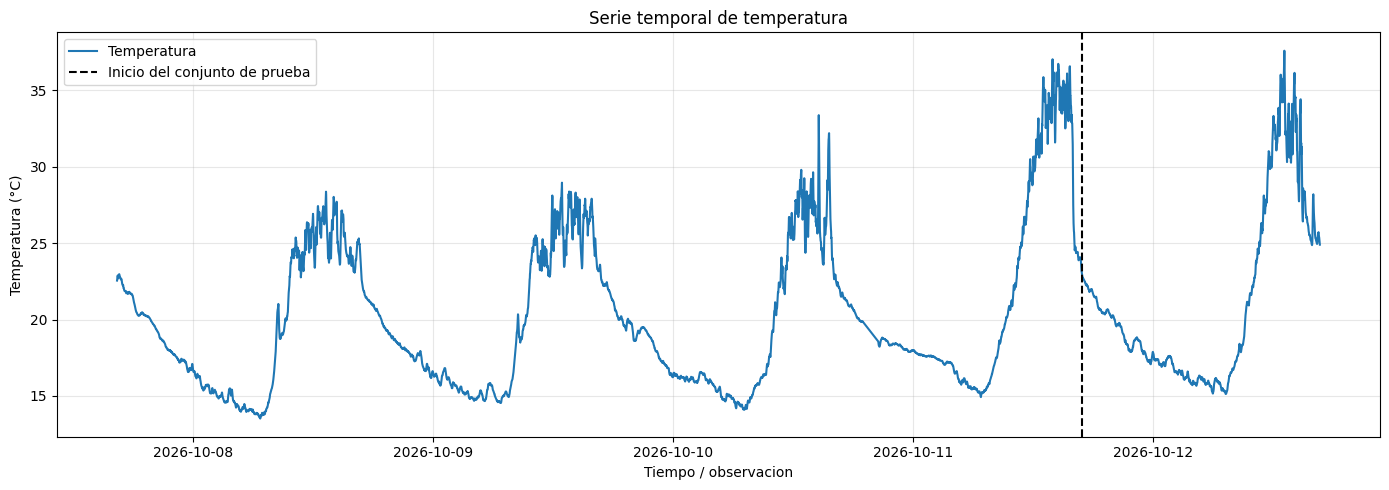

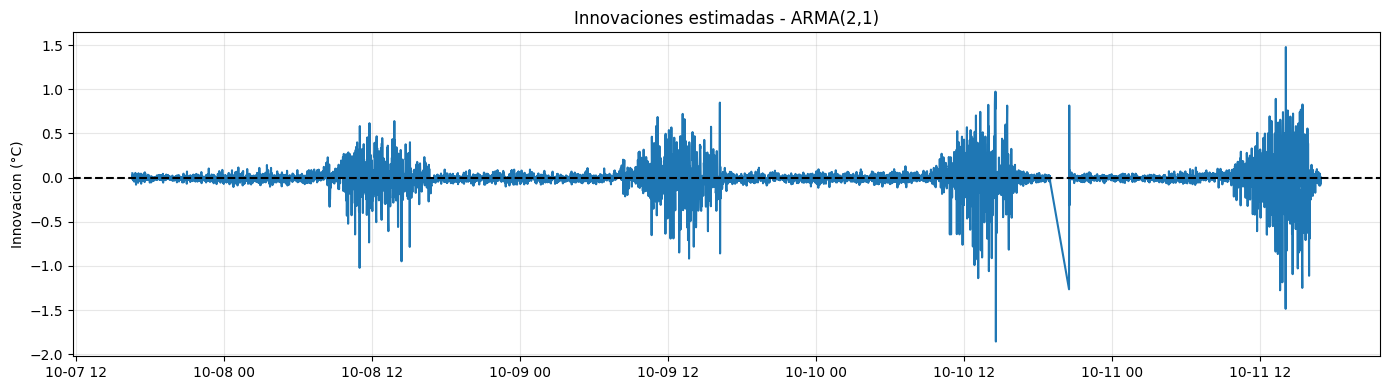

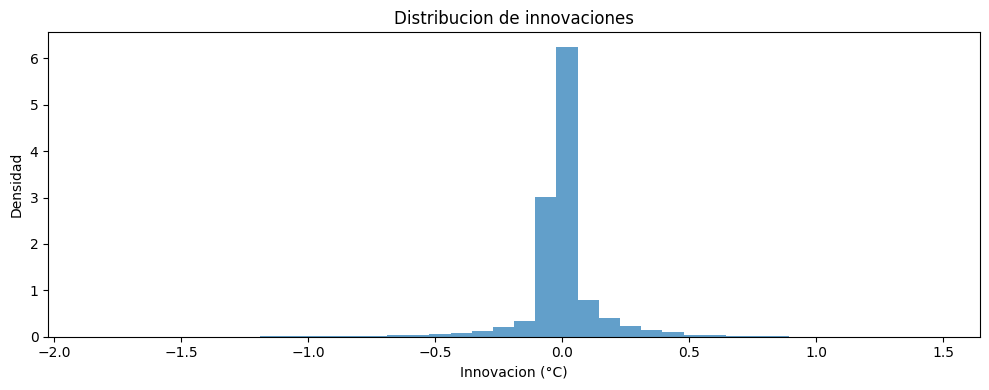

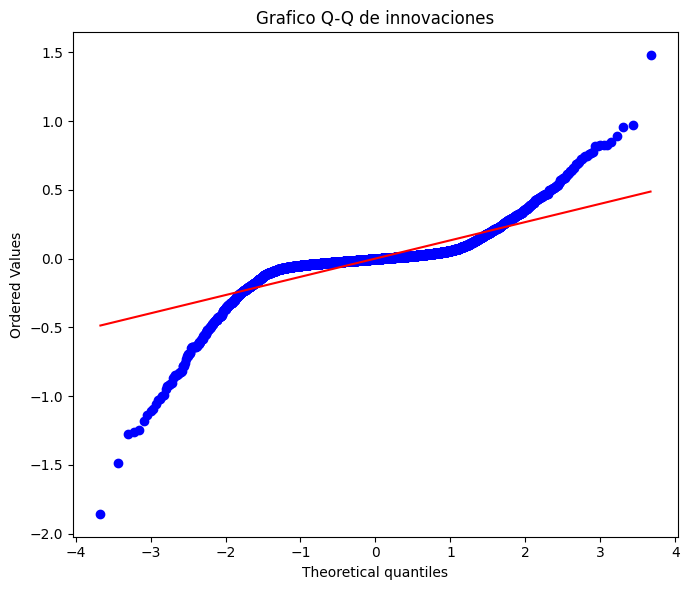

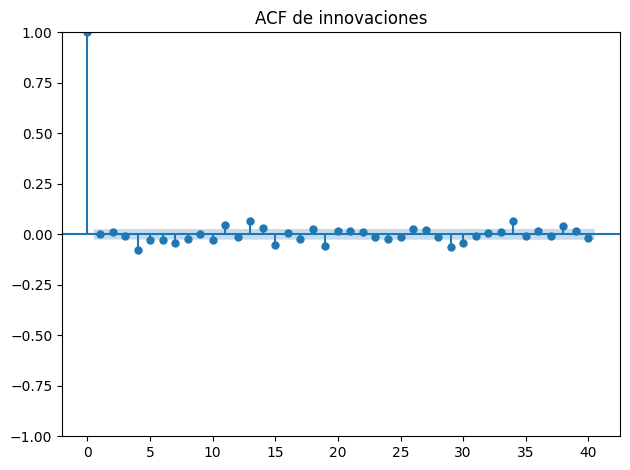

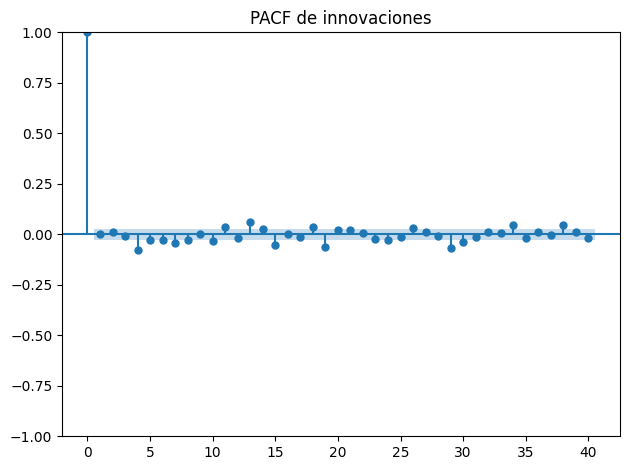

ValueError: No supported index is available.

In [4]:
# ============================================================
# MODELO ARMA(2,1) - TEMPERATURA AMBIENTAL
# Google Colab
# Estimación, innovaciones, AIC/BIC, residuales y predicciones
# ============================================================

!pip -q install openpyxl statsmodels scipy

import io
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 1. CONFIGURACION
# ------------------------------------------------------------

P = 2
D = 0
Q = 1

FRACCION_TRAIN = 0.80
HORIZONTES = [1, 3, 6, 12, 24]
N_FUTURO = max(HORIZONTES)

# Para datos cada 5 minutos, utilizar "5min".
# Si no se conoce la frecuencia, dejar None.
FRECUENCIA = None

# Definición manual de las columnas para solucionar el error de detección
COLUMNA_TEMPERATURA = "T"
COLUMNA_FECHA = "Fecha"
COLUMNA_HORA = "Hora" # Columna adicional para no perder la resolución temporal

# Numero de rezagos para graficos y diagnostico.
MAX_LAGS = 40

# Directorio de resultados
SALIDA = "/content/resultados_ARMA_21"
os.makedirs(SALIDA, exist_ok=True)

# ------------------------------------------------------------
# 2. CARGA DE DATOS
# ------------------------------------------------------------

print("=" * 65)
print("CARGA DEL DATASET")
print("=" * 65)

uploaded = files.upload()

if not uploaded:
    raise ValueError("No se cargo ningun archivo.")

nombre = next(iter(uploaded.keys()))
contenido = io.BytesIO(uploaded[nombre])

if nombre.lower().endswith(".csv"):
    try:
        df = pd.read_csv(contenido, sep=None, engine="python")
    except UnicodeDecodeError:
        contenido.seek(0)
        df = pd.read_csv(
            contenido, sep=None, engine="python",
            encoding="latin-1"
        )
elif nombre.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(contenido)
else:
    raise ValueError("Formato no soportado. Use CSV o Excel.")

df.columns = [str(c).strip() for c in df.columns]

print("\nArchivo:", nombre)
print("Dimensiones:", df.shape)
print("\nColumnas disponibles:")
print(df.columns.tolist())
print("\nPrimeras observaciones:")
print(df.head())

# ------------------------------------------------------------
# 3. IDENTIFICACION DE VARIABLES
# ------------------------------------------------------------

def normalizar(texto):
    import unicodedata
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(
        c for c in texto if not unicodedata.combining(c)
    )
    return texto.lower().strip()

if COLUMNA_TEMPERATURA is None:
    candidatos = [
        c for c in df.columns
        if "temp" in normalizar(c)
        and (
            "avg" in normalizar(c)
            or "prom" in normalizar(c)
            or "mean" in normalizar(c)
        )
    ]

    if not candidatos:
        candidatos = [
            c for c in df.columns
            if "temp" in normalizar(c)
        ]

    if not candidatos:
        raise ValueError(
            "No se identifico la temperatura. "
            "Defina COLUMNA_TEMPERATURA manualmente."
        )

    COLUMNA_TEMPERATURA = candidatos[0]

print("\nColumna seleccionada:", COLUMNA_TEMPERATURA)

if COLUMNA_FECHA is None:
    candidatos_fecha = [
        c for c in df.columns
        if any(
            palabra in normalizar(c)
            for palabra in ["fecha", "date", "time", "timestamp"]
        )
    ]
    if candidatos_fecha:
        COLUMNA_FECHA = candidatos_fecha[0]

# ------------------------------------------------------------
# 4. LIMPIEZA Y ORDENAMIENTO
# ------------------------------------------------------------

datos = pd.DataFrame()

datos["Temperatura"] = pd.to_numeric(
    df[COLUMNA_TEMPERATURA],
    errors="coerce"
)

if COLUMNA_FECHA is not None:
    # Combinar fecha y hora para evitar que colapsen las observaciones al mismo día
    if COLUMNA_HORA in df.columns:
        fecha_combinada = df[COLUMNA_FECHA].astype(str) + " " + df[COLUMNA_HORA].astype(str)
    else:
        fecha_combinada = df[COLUMNA_FECHA]

    datos["Fecha"] = pd.to_datetime(
        fecha_combinada,
        errors="coerce",
        dayfirst=True
    )

    datos = datos.dropna(subset=["Fecha"])
    datos = datos.sort_values("Fecha")
    datos = datos.drop_duplicates(subset=["Fecha"])

    datos = datos.set_index("Fecha")

    if FRECUENCIA is not None:
        # No interpolar automaticamente huecos extensos.
        datos = datos.resample(FRECUENCIA).mean()

        faltantes = datos["Temperatura"].isna().sum()

        if faltantes > 0:
            raise ValueError(
                f"Existen {faltantes} registros faltantes "
                "en la frecuencia especificada. "
                "Revise los huecos antes de ajustar ARMA."
            )

else:
    datos = datos.reset_index(drop=True)

faltantes = datos["Temperatura"].isna().sum()

print("\nValores faltantes de temperatura:", faltantes)

if faltantes > 0:
    raise ValueError(
        "La serie contiene temperaturas faltantes. "
        "Se requiere depuracion previa para preservar "
        "la estructura temporal."
    )

serie = datos["Temperatura"].astype(float)

if not np.isfinite(serie.to_numpy()).all():
    raise ValueError("La serie contiene valores no finitos.")

if len(serie) < 60:
    raise ValueError(
        f"Se recomiendan al menos 60 observaciones para ejecutar este analisis didactico. (La serie actual tiene {len(serie)} observaciones)"
    )

if isinstance(serie.index, pd.DatetimeIndex):
    diferencias = serie.index.to_series().diff().dropna()
    print("\nIntervalos temporales mas frecuentes:")
    print(diferencias.value_counts().head())

    if diferencias.nunique() > 1:
        print(
            "\nADVERTENCIA: Los intervalos no son uniformes. "
            "ARMA interpreta cada fila como un paso temporal. "
            "Regularice la serie antes de interpretar "
            "horizontes en minutos u horas."
        )

print("\nEstadistica descriptiva:")
print(serie.describe())

# ------------------------------------------------------------
# 5. PARTICION CRONOLOGICA
# ------------------------------------------------------------

n = len(serie)
n_train = int(n * FRACCION_TRAIN)

train = serie.iloc[:n_train]
test = serie.iloc[n_train:]

print("\nTotal:", n)
print("Entrenamiento:", len(train))
print("Prueba:", len(test))

# ------------------------------------------------------------
# 6. ESTACIONARIEDAD: ADF Y KPSS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("PRUEBAS DE ESTACIONARIEDAD - TRAIN")
print("=" * 65)

adf_resultado = adfuller(train, autolag="AIC")

print("\nADF:")
print("Estadistico:", adf_resultado[0])
print("p-valor:", adf_resultado[1])

try:
    kpss_resultado = kpss(
        train, regression="c", nlags="auto"
    )
    print("\nKPSS:")
    print("Estadistico:", kpss_resultado[0])
    print("p-valor:", kpss_resultado[1])
    p_kpss = kpss_resultado[1]
except Exception as exc:
    print("KPSS no disponible:", exc)
    p_kpss = np.nan

if adf_resultado[1] >= 0.05:
    print("\nADVERTENCIA: ADF no rechaza raiz unitaria.")

if np.isfinite(p_kpss) and p_kpss < 0.05:
    print("\nADVERTENCIA: KPSS rechaza estacionariedad.")

print(
    "\nIMPORTANTE: Las pruebas no sustituyen el analisis "
    "de tendencia, estacionalidad y cambios estructurales."
)

# ------------------------------------------------------------
# 7. ESTIMACION ARMA(2,1)
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("ESTIMACION DE PARAMETROS")
print("=" * 65)

modelo = ARIMA(
    train,
    order=(P, D, Q),
    trend="c",
    enforce_stationarity=True,
    enforce_invertibility=True
)

ajuste = modelo.fit()

print(ajuste.summary())

parametros = ajuste.params

phi1 = parametros["ar.L1"]
phi2 = parametros["ar.L2"]
theta1 = parametros["ma.L1"]
mu = parametros["const"]
sigma2 = parametros["sigma2"]

# statsmodels utiliza const como media incondicional
# para ARIMA estacionario con d=0.
intercepto = mu * (1 - phi1 - phi2)

print("\nPARAMETROS OPTIMIZADOS")
print(f"Media incondicional mu: {mu:.8f}")
print(f"Intercepto c:          {intercepto:.8f}")
print(f"phi1:                  {phi1:.8f}")
print(f"phi2:                  {phi2:.8f}")
print(f"theta1:                {theta1:.8f}")
print(f"Varianza sigma2:       {sigma2:.8f}")

print("\nCRITERIOS DE INFORMACION")
print(f"AIC: {ajuste.aic:.6f}")
print(f"BIC: {ajuste.bic:.6f}")
print(f"Log-verosimilitud: {ajuste.llf:.6f}")

# ------------------------------------------------------------
# 8. TABLA DE REZAGOS E INNOVACIONES
# ------------------------------------------------------------

# Las innovaciones de statsmodels proceden del filtrado
# del modelo estimado. No son exactamente iguales a
# las innovaciones de una recursion condicional iniciada
# con ceros.

innovaciones = pd.Series(
    np.asarray(ajuste.resid),
    index=train.index,
    name="Innovacion_estimada"
)

valores_ajustados = pd.Series(
    np.asarray(ajuste.fittedvalues),
    index=train.index,
    name="Temperatura_ajustada"
)

tabla = pd.DataFrame(index=train.index)

tabla["T_t"] = train
tabla["T_t-1"] = train.shift(1)
tabla["T_t-2"] = train.shift(2)

tabla["Innovacion_t-1"] = innovaciones.shift(1)

tabla["T_ajustada"] = valores_ajustados
tabla["Innovacion_t"] = innovaciones

tabla["Error_cuadrado"] = innovaciones**2

# Prediccion estructural usando la ecuacion ARMA.
# Las primeras filas dependen de la inicializacion.
tabla["Prediccion_ecuacion"] = (
    intercepto
    + phi1 * tabla["T_t-1"]
    + phi2 * tabla["T_t-2"]
    + theta1 * tabla["Innovacion_t-1"]
)

print("\nTABLA DE REZAGOS E INNOVACIONES")
print(tabla.head(15).to_string())

tabla.to_csv(
    os.path.join(SALIDA, "tabla_rezagos_innovaciones.csv"),
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 9. ANALISIS RESIDUAL
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DIAGNOSTICO RESIDUAL")
print("=" * 65)

# Descartar primeras observaciones para reducir
# influencia de la inicializacion del filtro.
burn = max(10, P + Q + 1)

resid = innovaciones.iloc[burn:].dropna()

print("Media residual:", resid.mean())
print("Desviacion estandar:", resid.std())
print("RMSE residual:", np.sqrt(np.mean(resid**2)))

lags = min(MAX_LAGS, len(resid)//4)

if lags < 2:
    raise ValueError("Muy pocos residuales para diagnostico.")

lb = acorr_ljungbox(
    resid,
    lags=[lags],
    model_df=P + Q,
    return_df=True
)

print("\nPRUEBA DE LJUNG-BOX")
print(lb)

if np.isfinite(lb["lb_pvalue"].iloc[0]):
    if lb["lb_pvalue"].iloc[0] > 0.05:
        print("No se rechaza ausencia de autocorrelacion.")
    else:
        print("Se detecta evidencia de autocorrelacion.")
else:
    print("Prueba no concluyente.")

# ------------------------------------------------------------
# 10. GRAFICAS DE LA SERIE
# ------------------------------------------------------------

plt.figure(figsize=(14, 5))
plt.plot(serie.index, serie.values, label="Temperatura")
plt.axvline(
    x=serie.index[n_train],
    color="black",
    linestyle="--",
    label="Inicio del conjunto de prueba"
)
plt.title("Serie temporal de temperatura")
plt.xlabel("Tiempo / observacion")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "serie_temperatura.png"),
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 11. GRAFICAS DE RESIDUALES
# ------------------------------------------------------------

plt.figure(figsize=(14, 4))
plt.plot(resid.index, resid.values)
plt.axhline(0, color="black", linestyle="--")
plt.title("Innovaciones estimadas - ARMA(2,1)")
plt.ylabel("Innovacion (°C)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "innovaciones.png"),
    dpi=180
)
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(resid, bins=40, density=True, alpha=0.7)
plt.title("Distribucion de innovaciones")
plt.xlabel("Innovacion (°C)")
plt.ylabel("Densidad")
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "histograma_residuales.png"),
    dpi=180
)
plt.show()

plt.figure(figsize=(7, 6))
stats.probplot(resid, dist="norm", plot=plt)
plt.title("Grafico Q-Q de innovaciones")
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "qq_residuales.png"),
    dpi=180
)
plt.show()

plot_acf(resid, lags=lags)
plt.title("ACF de innovaciones")
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "acf_residuales.png"),
    dpi=180
)
plt.show()

plot_pacf(
    resid,
    lags=min(lags, len(resid)//2 - 1),
    method="ywm"
)
plt.title("PACF de innovaciones")
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "pacf_residuales.png"),
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 12. PREDICCION SOBRE EL CONJUNTO DE PRUEBA
# ------------------------------------------------------------

# Pronostico genuino desde el final de train.
# No utiliza observaciones del conjunto test
# para actualizar las predicciones.

pronostico_test = ajuste.get_forecast(steps=len(test))

y_pred = pd.Series(
    np.asarray(pronostico_test.predicted_mean),
    index=test.index
)

intervalos = np.asarray(
    pronostico_test.conf_int(alpha=0.05)
)

mae = mean_absolute_error(test, y_pred)
rmse = np.sqrt(mean_squared_error(test, y_pred))

# Referencia: persistencia del ultimo valor train
baseline = np.full(len(test), train.iloc[-1])

mae_base = mean_absolute_error(test, baseline)
rmse_base = np.sqrt(mean_squared_error(test, baseline))

print("\n" + "=" * 65)
print("EVALUACION EN TEST")
print("=" * 65)

print(f"MAE ARMA: {mae:.6f}")
print(f"RMSE ARMA: {rmse:.6f}")
print(f"MAE referencia: {mae_base:.6f}")
print(f"RMSE referencia: {rmse_base:.6f}")

tabla_test = pd.DataFrame({
    "Temperatura_real": test.to_numpy(),
    "Prediccion_ARMA": y_pred.to_numpy(),
    "Limite_inferior_95": intervalos[:, 0],
    "Limite_superior_95": intervalos[:, 1],
    "Error": test.to_numpy() - y_pred.to_numpy()
}, index=test.index)

tabla_test.to_csv(
    os.path.join(SALIDA, "predicciones_test.csv"),
    encoding="utf-8-sig"
)

plt.figure(figsize=(14, 5))
plt.plot(
    test.index, test.values,
    label="Temperatura real",
    linewidth=1.5
)
plt.plot(
    test.index, y_pred.values,
    label="ARMA(2,1)",
    linewidth=1.5
)
plt.fill_between(
    np.arange(len(test)),
    np.nan, np.nan
) if False else None

plt.title("Prediccion ARMA(2,1) en conjunto de prueba")
plt.xlabel("Tiempo / observacion")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(SALIDA, "prediccion_test.png"),
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 13. PRONOSTICOS FUTUROS
# ------------------------------------------------------------

# Reajuste con toda la serie, exclusivamente para
# generar el pronostico final despues de la evaluacion.

modelo_final = ARIMA(
    serie,
    order=(2, 0, 1),
    trend="c",
    enforce_stationarity=True,
    enforce_invertibility=True
)

ajuste_final = modelo_final.fit()

futuro = ajuste_final.get_forecast(steps=N_FUTURO)

media_futura = np.asarray(futuro.predicted_mean)
ic_futuro = np.asarray(futuro.conf_int(alpha=0.05))

tabla_futuro = pd.DataFrame({
    "Horizonte": np.arange(1, N_FUTURO + 1),
    "Prediccion": media_futura,
    "Limite_inferior_95": ic_futuro[:, 0],
    "Limite_superior_95": ic_futuro[:, 1]
})

print("\nPREDICCIONES EN HORIZONTES SELECCIONADOS")
print(
    tabla_futuro[
        tabla_futuro["Horizonte"].isin(HORIZONTES)
    ].to_string(index=False)
)

tabla_futuro.to_csv(
    os.path.join(SALIDA, "predicciones_futuras.csv"),
    index=False,
    encoding="utf-8-sig"
)

plt.figure(figsize=(12, 5))

plt.plot(
    tabla_futuro["Horizonte"],
    tabla_futuro["Prediccion"],
    marker="o",
    label="Prediccion ARMA"
)

plt.fill_between(
    tabla_futuro["Horizonte"],
    tabla_futuro["Limite_inferior_95"],
    tabla_futuro["Limite_superior_95"],
    alpha=0.2,
    label="Intervalo predictivo 95%"
)

plt.axhline(
    serie.mean(),
    color="gray",
    linestyle="--",
    label="Media historica"
)

plt.title("Predicciones futuras ARMA(2,1)")
plt.xlabel("Horizonte (numero de observaciones)")
plt.ylabel("Temperatura (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(SALIDA, "predicciones_futuras.png"),
    dpi=180
)
plt.show()

# ------------------------------------------------------------
# 14. EXPORTACION DE RESULTADOS
# ------------------------------------------------------------

resumen = pd.DataFrame({
    "Indicador": [
        "AR_p", "MA_q", "Media_mu", "Intercepto_c",
        "Phi_1", "Phi_2", "Theta_1",
        "Sigma2", "AIC", "BIC", "LogLik",
        "MAE_test", "RMSE_test",
        "MAE_referencia", "RMSE_referencia"
    ],
    "Valor": [
        P, Q, mu, intercepto,
        phi1, phi2, theta1,
        sigma2, ajuste.aic, ajuste.bic, ajuste.llf,
        mae, rmse, mae_base, rmse_base
    ]
})

ruta_excel = os.path.join(
    SALIDA, "resultados_completos_ARMA_21.xlsx"
)

with pd.ExcelWriter(ruta_excel, engine="openpyxl") as writer:
    resumen.to_excel(
        writer, sheet_name="Parametros", index=False
    )
    tabla.to_excel(
        writer, sheet_name="Rezagos_Innovaciones"
    )
    tabla_test.to_excel(
        writer, sheet_name="Evaluacion_Test"
    )
    tabla_futuro.to_excel(
        writer, sheet_name="Predicciones_Futuras",
        index=False
    )
    lb.to_excel(
        writer, sheet_name="Ljung_Box"
    )

print("\n" + "=" * 65)
print("ANALISIS FINALIZADO")
print("=" * 65)
print("Resultados guardados en:", SALIDA)
print("Archivo Excel:", ruta_excel)

files.download(ruta_excel)